# فاز دوم — گام دوم: متغیر تصادفی گسسته و توزیع دوجمله‌ای
**مسیر الف: NHANES 2021–2023** | ادامهٔ مستقیم فاز اول و گام اول فاز دوم

در این گام، رویداد از پیش تعریف‌شدهٔ گام اول حفظ می‌شود:

$$A=\{D<50\,\mathrm{nmol/L}\}.$$

**پرسش:** اگر ۳۰ بزرگسال را به‌صورت تصادفی از افراد دارای دادهٔ معتبر انتخاب کنیم، تعداد افراد با ویتامین D کمتر از ۵۰ چه توزیعی دارد؟ مدل دوجمله‌ای تحت چه فرض‌هایی تقریب قابل قبولی است؟

- دادهٔ اصلی: فایل محلی `final_data.csv` که با ادغام داده‌ها در **فاز اول** ساخته شده است.
- در GitHub فقط نوت‌بوک، نمودارها و جدول‌های خلاصه نگهداری می‌شوند، **نه** فایل دادهٔ فردی.
- بازنمونه‌گیری این بخش یک *نمایش آموزشیِ رفتار شمارش* است، نه Bootstrap برای برآورد خطای نمونه‌گیری NHANES.

## ۱. تعریف متغیر تصادفی و فرض‌های مدل

برای فرد $i$، متغیر برنولی زیر را تعریف می‌کنیم:

$$Y_i=\mathbf 1(D_i<50), \qquad Y_i\in\{0,1\}.$$

در گروهی با اندازهٔ ثابت $n=30$، شمارش افراد زیر آستانه:

$$X=\sum_{i=1}^{30}Y_i.$$

**مدل دوجمله‌ای** $X\sim\mathrm{Binomial}(n,p)$ فقط زمانی دقیق است که در هر ۳۰ آزمون: تعداد آزمون‌ها ثابت، پیامد دودویی، احتمال $p$ یکسان و رخدادها مستقل باشند. در آن صورت:

$$\Pr(X=k)={30\choose k}p^k(1-p)^{30-k},\quad E(X)=30p,\quad \operatorname{Var}(X)=30p(1-p).$$

**تفکیک علمی ضروری:** نمونهٔ واقعی NHANES چندمرحله‌ای، طبقه‌بندی‌شده و خوشه‌ای است؛ بنابراین نباید مستقل و هم‌توزیع بودن مشاهدات آن را بدون بررسی فرض کرد. در این گام، برای مقایسهٔ آموزشی، از داده‌های موجود «زیرنمونه‌های تصادفی سادهٔ هم‌اندازه بدون جایگذاری» می‌کشیم؛ توزیع *دقیق* این شمارش در چارچوب دادهٔ ثابت، **فوق‌هندسی** (Hypergeometric) است و دوجمله‌ای تقریب آن خواهد بود. نتیجه را به طرح واقعی NHANES تعمیم نمی‌دهیم.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom, hypergeom
from IPython.display import display

N_GROUP = 30
N_REPEATS = 5000
RANDOM_SEED = 1405
THRESHOLD = 50.0

# Find the repository/project root whether Jupyter was launched from the
# repository root, its notebooks/ folder, or a standalone location.
where = Path.cwd().resolve()
roots = [where, where.parent, where.parent.parent]
project_root = next((p for p in roots if (p / '.git').exists() or (p / 'PROJECT_CARD.md').exists()), where)

# The working data may live in the original local project; it is NOT required
# to be copied into the GitHub clone.
search_paths = [
    project_root / 'data' / 'final_data.csv',
    project_root / 'final_data.csv',
    project_root.parent / 'vitamin-d-project' / 'data' / 'final_data.csv',
    project_root.parent / 'vitamin-d-project' / 'final_data.csv',
    where / 'data' / 'final_data.csv',
    where / 'final_data.csv',
    where.parent / 'data' / 'final_data.csv',
    where.parent / 'final_data.csv',
    Path.home() / 'Documents' / 'vitamin-d-project' / 'data' / 'final_data.csv',
    Path.home() / 'Documents' / 'vitamin-d-project' / 'final_data.csv',
]
# Remove duplicates while preserving order.
search_paths = list(dict.fromkeys(p.resolve() for p in search_paths))
data_path = next((p for p in search_paths if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError('Cannot find final_data.csv from Phase 1. Checked:\n' + '\n'.join(map(str, search_paths)))

data = pd.read_csv(data_path, low_memory=False)
needed = ['SEQN', 'RIDAGEYR', 'LBXVIDMS', 'RIAGENDR', 'WTPH2YR_clean']
missing = sorted(set(needed) - set(data.columns))
if missing:
    raise ValueError(f'Missing Phase 1 columns: {missing}')
for column in needed:
    data[column] = pd.to_numeric(data[column], errors='coerce')
if data['SEQN'].isna().any() or data['SEQN'].duplicated().any():
    raise ValueError('SEQN is missing or duplicated. Check Phase 1 data merging.')

valid = data.loc[
    data['RIDAGEYR'].ge(18) &
    data['LBXVIDMS'].notna() &
    data['RIAGENDR'].isin([1, 2]) &
    data['WTPH2YR_clean'].gt(0)
].copy()
valid['A'] = valid['LBXVIDMS'] < THRESHOLD
N = len(valid)
K = int(valid['A'].sum())
assert N_GROUP < N and N > 0
p_raw = K / N
p_weighted = float(np.average(valid['A'].astype(float), weights=valid['WTPH2YR_clean']))
assert N == 5824 and K == 1177, f'Unexpected data: N={N}, K={K}. Compare the Phase 1 export.'

fig_dir = project_root / 'figures' / 'phase2'
report_dir = project_root / 'reports' / 'phase2'
fig_dir.mkdir(parents=True, exist_ok=True)
report_dir.mkdir(parents=True, exist_ok=True)

print('Phase 1 data:', data_path)
print('Analysis population:', N)
print('A = D < 50 (count):', K)
print(f'Unweighted P(A): {p_raw:.6f} = {100*p_raw:.2f}%')
print(f'Weighted P(A): {p_weighted:.6f} = {100*p_weighted:.2f}%')
print('Output figures:', fig_dir)
print('Output tables:', report_dir)

Phase 1 data: /mnt/data/final_data.csv
Analysis population: 5824
A = D < 50 (count): 1177
Unweighted P(A): 0.202095 = 20.21%
Weighted P(A): 0.208383 = 20.84%
Output figures: /mnt/data/figures/phase2
Output tables: /mnt/data/reports/phase2


## ۲. دو احتمال متفاوت و کاربرد آن‌ها

1. **$\hat p_{raw}=K/N$**: سهم افراد زیر آستانه در خود فایل نمونه؛ برای زیرنمونه‌گیری تصادفی سادهٔ بدون جایگذاری از **همین ۵٬۸۲۴ نفر**، این مقدار مبنای درست توزیع فوق‌هندسی و تقریب دوجمله‌ای است.
2. **$\hat p_{w}$**: احتمال تجربی وزن‌دار برای تفسیر جمعیتی در چارچوب وزن‌های خون‌گیری؛ این مقدار برای یک **سناریوی فرضی از آزمون‌های مستقل با احتمال برابر** می‌تواند پارامتر مدل دوجمله‌ای باشد، نه برای توصیف مستقیم سازوکار نمونه‌گیری NHANES.

بنابراین منحنی دوجمله‌ایِ وزن‌دار را فقط به‌عنوان *سناریوی فرضی* نشان می‌دهیم؛ آن را با شمارش‌های حاصل از نمونه‌گیری بدون وزن یکی نمی‌گیریم.

In [2]:
mean_bin_raw = N_GROUP * p_raw
var_bin_raw = N_GROUP * p_raw * (1 - p_raw)
finite_correction = (N - N_GROUP) / (N - 1)
var_hypergeom = var_bin_raw * finite_correction

print(f'Binomial (raw p): E[X]={mean_bin_raw:.4f}, Var(X)={var_bin_raw:.4f}, SD={np.sqrt(var_bin_raw):.4f}')
print(f'Hypergeometric exact: E[X]={N_GROUP*K/N:.4f}, Var(X)={var_hypergeom:.4f}')
print(f'Finite-population variance factor: {finite_correction:.6f}')
print(f'Binomial (weighted p, hypothetical): E[X]={N_GROUP*p_weighted:.4f}, Var(X)={N_GROUP*p_weighted*(1-p_weighted):.4f}')

Binomial (raw p): E[X]=6.0628, Var(X)=4.8376, SD=2.1994
Hypergeometric exact: E[X]=6.0628, Var(X)=4.8135
Finite-population variance factor: 0.995020
Binomial (weighted p, hypothetical): E[X]=6.2515, Var(X)=4.9488


## ۳. زیرنمونه‌های هم‌اندازه — شبیه‌سازی آموزشی

در هر بار اجرا، ۳۰ فرد از میان ۵٬۸۲۴ مشاهدهٔ واجد شرایط **بدون جایگذاری در همان زیرنمونه** انتخاب می‌شوند. این فرایند ۵۰۰۰ بار با بذر تصادفی ثابت تکرار می‌شود تا شکل توزیع شمارش $X$ دیده شود. یک فرد می‌تواند در تکرارهای متفاوت دوباره انتخاب شود؛ تکرارها جای «نمونه‌های مستقلِ طرح NHANES» را نمی‌گیرند.

برای جمعیت متناهی با $N=5824$ و $K=1177$ فرد دارای رویداد، توزیع شمارش یک زیرنمونهٔ $n=30$ نفره دقیقاً چنین است:

$$X\sim\operatorname{Hypergeometric}(N=5824,K=1177,n=30).$$

چون $n/N$ کوچک است، دوجمله‌ای با $p=K/N$ باید تقریب نزدیکی بدهد. این نزدیکی از نظر ریاضی با *اصلاح جامعه متناهی* توضیح داده می‌شود، نه با اثبات استقلال در نمونه‌گیری NHANES.

In [3]:
rng = np.random.default_rng(RANDOM_SEED)
a_values = valid['A'].to_numpy(dtype=np.int8)

# Each row is a new size-30 subgroup sampled without replacement. A respondent
# may appear again in a DIFFERENT simulation iteration, which is intentional.
counts = np.array([
    int(a_values[rng.choice(N, size=N_GROUP, replace=False)].sum())
    for _ in range(N_REPEATS)
], dtype=int)
assert len(counts) == N_REPEATS
assert np.all((counts >= 0) & (counts <= N_GROUP))

k_values = np.arange(N_GROUP + 1)
observed_pmf = np.bincount(counts, minlength=N_GROUP + 1) / N_REPEATS
exact_pmf = hypergeom.pmf(k_values, M=N, n=K, N=N_GROUP)
bin_raw_pmf = binom.pmf(k_values, n=N_GROUP, p=p_raw)
bin_w_pmf = binom.pmf(k_values, n=N_GROUP, p=p_weighted)

for pmf in (observed_pmf, exact_pmf, bin_raw_pmf, bin_w_pmf):
    assert np.isclose(pmf.sum(), 1.0, atol=1e-10)

sim_mean = float(counts.mean())
sim_variance = float(counts.var(ddof=0))
max_pmf_difference = float(np.max(np.abs(exact_pmf - bin_raw_pmf)))
print(f'Subgroup size: {N_GROUP}; repetitions: {N_REPEATS}; RNG seed: {RANDOM_SEED}')
print(f'Simulated mean count: {sim_mean:.4f} (theoretical {mean_bin_raw:.4f})')
print(f'Simulated variance: {sim_variance:.4f} (hypergeometric {var_hypergeom:.4f})')
print(f'Maximum PMF gap: exact hypergeometric vs binomial(raw) = {max_pmf_difference:.6f}')

Subgroup size: 30; repetitions: 5000; RNG seed: 1405
Simulated mean count: 6.1310 (theoretical 6.0628)
Simulated variance: 4.9966 (hypergeometric 4.8135)
Maximum PMF gap: exact hypergeometric vs binomial(raw) = 0.000460


## ۴. نمودار اصلی: شمارش مشاهده‌شده در زیرنمونه‌ها و مدل‌ها

ستون‌ها فراوانی نسبی شمارش رویداد در ۵۰۰۰ زیرنمونهٔ ۳۰ نفره هستند. خط اول احتمال نظری **فوق‌هندسی** را نمایش می‌دهد و خط دوم تقریب **دوجمله‌ای با احتمال خام** را. نزدیکی منحنی‌ها به معنای تأیید استقلال طرح اصلی NHANES نیست.

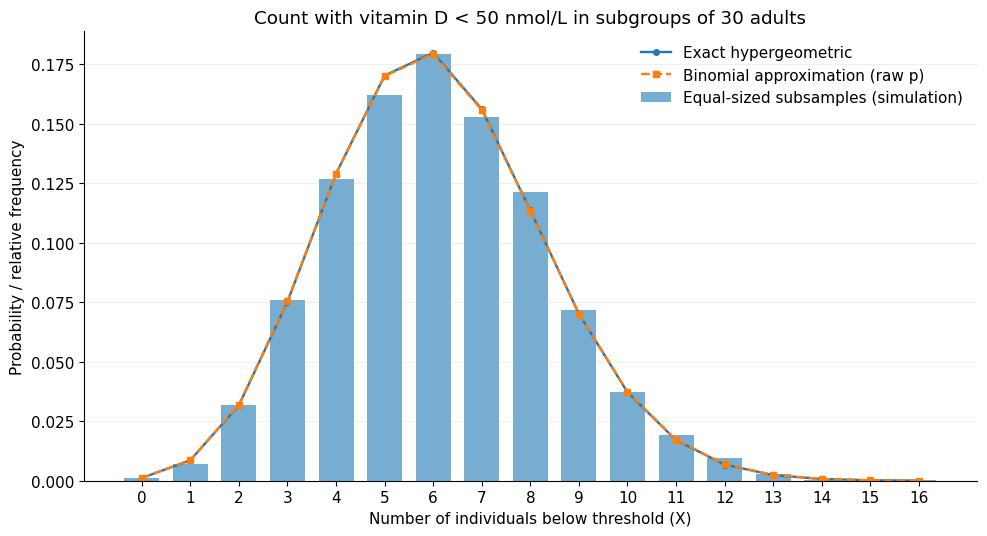

Saved: /mnt/data/figures/phase2/phase2_step2_subsamples_vs_binomial.png


In [4]:
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
fig, ax = plt.subplots(figsize=(10, 5.5))
visible = np.arange(0, 17)
ax.bar(visible, observed_pmf[visible], width=0.72, alpha=0.60, label='Equal-sized subsamples (simulation)')
ax.plot(visible, exact_pmf[visible], 'o-', linewidth=1.7, markersize=4, label='Exact hypergeometric')
ax.plot(visible, bin_raw_pmf[visible], 's--', linewidth=1.7, markersize=4, label='Binomial approximation (raw p)')
ax.set_title('Count with vitamin D < 50 nmol/L in subgroups of 30 adults')
ax.set_xlabel('Number of individuals below threshold (X)')
ax.set_ylabel('Probability / relative frequency')
ax.set_xticks(visible)
ax.set_ylim(bottom=0)
ax.grid(axis='y', alpha=0.18)
ax.legend(frameon=False)
fig.tight_layout()
fig_path = fig_dir / 'phase2_step2_subsamples_vs_binomial.png'
fig.savefig(fig_path, dpi=190, bbox_inches='tight')
plt.show()
print('Saved:', fig_path)

## ۵. اثر وزن‌دهی بر پارامتر مدل — فقط مقایسهٔ دو سناریوی فرضی

با احتمال خام $p_{raw}$، تعداد مورد انتظار افراد زیر آستانه در ۳۰ آزمون مستقل برابر $30p_{raw}$ است. با احتمال وزن‌دار $p_w$، این مقدار $30p_w$ می‌شود. نمودار زیر **دو مدل نظری دوجمله‌ای** را مقایسه می‌کند؛ هیچ‌کدام ادعا نمی‌کنند طرح خوشه‌ای NHANES را بازتولید کرده‌اند.

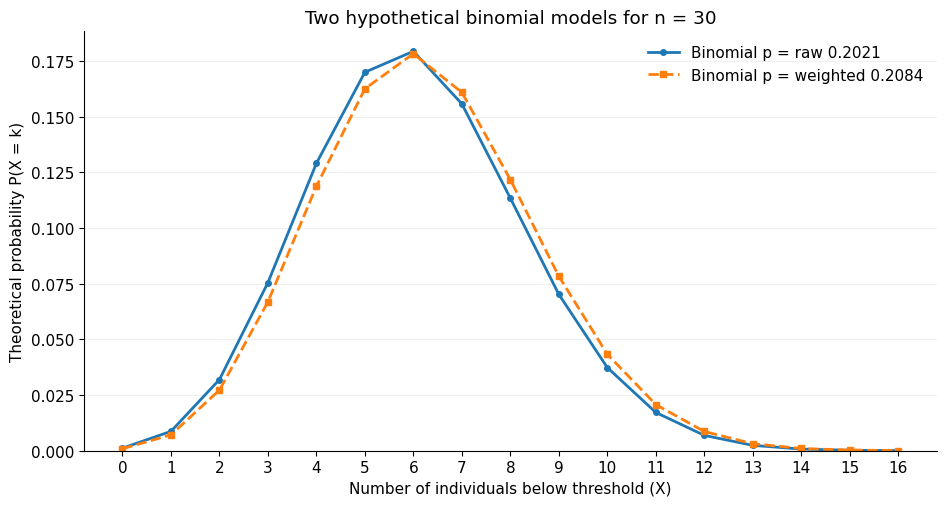

Saved: /mnt/data/figures/phase2/phase2_step2_weighted_vs_raw_scenarios.png


In [5]:
fig2, ax2 = plt.subplots(figsize=(9.6, 5.2))
ax2.plot(visible, bin_raw_pmf[visible], 'o-', linewidth=2, markersize=4, label=f'Binomial p = raw {p_raw:.4f}')
ax2.plot(visible, bin_w_pmf[visible], 's--', linewidth=2, markersize=4, label=f'Binomial p = weighted {p_weighted:.4f}')
ax2.set_title('Two hypothetical binomial models for n = 30')
ax2.set_xlabel('Number of individuals below threshold (X)')
ax2.set_ylabel('Theoretical probability P(X = k)')
ax2.set_xticks(visible)
ax2.set_ylim(bottom=0)
ax2.grid(axis='y', alpha=0.18)
ax2.legend(frameon=False)
fig2.tight_layout()
fig2_path = fig_dir / 'phase2_step2_weighted_vs_raw_scenarios.png'
fig2.savefig(fig2_path, dpi=190, bbox_inches='tight')
plt.show()
print('Saved:', fig2_path)

## ۶. جمع‌بندی و محدودیت‌های آماری

- رویداد، شمارش و توزیع گسسته تعریف شدند؛ مدل دوجمله‌ای چهار شرط مشخص دارد.
- انتخاب سادهٔ بدون جایگذاری از *افراد مشاهده‌شده* توزیع فوق‌هندسی دارد؛ به علت کم‌بودن کسر نمونه، دوجمله‌ای با $p_{raw}$ تقریب مناسبی برای این تمرین است.
- عدد $p_w$ از وزن‌های NHANES محاسبه می‌شود و برای تفسیر جمعیتی مهم است؛ استفاده از $\mathrm{Binomial}(30,p_w)$ فقط سناریوی فرضی مستقل است.
- این شبیه‌سازی **آزمون فرض، فاصله اطمینان، Bootstrap طراحی‌محور یا تأیید ساختار استقلال جمعیت آمریکا نیست**؛ این کارها به‌ویژه در طرح پیچیدهٔ NHANES نیازمند روش مناسب‌اند.

**منابع روش‌شناختی:**
1. [CDC: NHANES August 2021–August 2023 analytic guidance](https://wwwn.cdc.gov/Nchs/Nhanes/continuousnhanes/OverviewBrief.aspx?Cycle=2021-2023)
2. [CDC: NHANES weighting module](https://wwwn.cdc.gov/nchs/nhanes/tutorials/weighting.aspx)

خروجی‌های قابل ثبت در GitHub: دو شکل در `figures/phase2/`، دو جدول و متن یادداشت در `reports/phase2/`، و این نوت‌بوک در `notebooks/`. دادهٔ فردی باید فقط در رایانهٔ محلی نگهداری شود.

In [6]:
# Save only aggregate data, never participant-level observations.
comparison = pd.DataFrame({
    'count_k': k_values,
    'subsample_relative_frequency': observed_pmf,
    'hypergeometric_exact_pmf': exact_pmf,
    'binomial_raw_pmf': bin_raw_pmf,
    'binomial_weighted_hypothetical_pmf': bin_w_pmf,
})

summary = pd.DataFrame([
    ['eligible_adults_n', N],
    ['observed_event_count_K', K],
    ['event_rate_unweighted', p_raw],
    ['event_rate_weighted', p_weighted],
    ['subgroup_size_n', N_GROUP],
    ['subgroup_repetitions', N_REPEATS],
    ['binomial_raw_expected_count', mean_bin_raw],
    ['binomial_raw_variance', var_bin_raw],
    ['hypergeometric_expected_count', mean_bin_raw],
    ['hypergeometric_exact_variance', var_hypergeom],
    ['finite_population_variance_factor', finite_correction],
    ['simulated_subgroup_mean', sim_mean],
    ['simulated_subgroup_variance_ddof0', sim_variance],
    ['binomial_weighted_hypothetical_expected_count', N_GROUP*p_weighted],
    ['maximum_absolute_pmf_gap_hypergeom_vs_binom_raw', max_pmf_difference],
], columns=['indicator', 'value'])

comparison_path = report_dir / 'phase2_step2_count_distribution.csv'
summary_path = report_dir / 'phase2_step2_binomial_summary.csv'
comparison.to_csv(comparison_path, index=False, encoding='utf-8-sig')
summary.to_csv(summary_path, index=False, encoding='utf-8-sig')

def fa(x, digits=4):
    return f'{x:.{digits}f}'
notes = f"""# Phase 2 / Step 2 — Discrete count and binomial approximation

**Empirical NHANES August 2021–August 2023 file, inherited from Phase 1**

- Participants with valid D measurement and positive phlebotomy weight: N={N:,}.
- Participants below D<50 nmol/L: K={K:,}.
- Raw empirical probability: p_raw={fa(p_raw,6)}; survey-weighted probability: p_w={fa(p_weighted,6)}.
- Equal-sized simple random subsamples **without replacement**: n={N_GROUP}, repeated {N_REPEATS:,} times (seed {RANDOM_SEED}).
- Mean event count of the simulation: {fa(sim_mean)}; simulated variance: {fa(sim_variance)}.
- Binomial approximation with **raw** p: E(X)={fa(mean_bin_raw)}, Var(X)={fa(var_bin_raw)}.
- Exact finite-sample hypergeometric variance: {fa(var_hypergeom)}; finite population correction factor: {fa(finite_correction,6)}.
- Maximum pointwise absolute PMF difference (hypergeometric vs raw-p binomial): {fa(max_pmf_difference,6)}.
- Weighted p in a **hypothetical independent** Bernoulli model gives E(X)={fa(N_GROUP*p_weighted)}.

## Scientific interpretation

With a fixed set of N observed people and K observed events, repeated size-n SRS **without replacement** produces a hypergeometric count exactly, not a binomial count. Since n/N={100*N_GROUP/N:.3f}% is small, the binomial model using p_raw=K/N is a close approximation here. The original stratified and clustered NHANES probability sample does **not** meet independent-identically-distributed trial assumptions by default, and this teaching simulation does not reproduce its design. Weighted p changes the marginal population-oriented rate; Binomial(n,p_w) is a separate hypothetical scenario, not an NHANES sampling variance model.

No formal hypothesis test or confidence interval is reported in Phase 2 Step 2. Individual records must not be pushed to GitHub.
"""
notes_path = report_dir / 'step2_binomial_notes.md'
notes_path.write_text(notes, encoding='utf-8')
print('Saved summary:', summary_path)
print('Saved count distribution:', comparison_path)
print('Saved explanatory notes:', notes_path)
display(summary)

Saved summary: /mnt/data/reports/phase2/phase2_step2_binomial_summary.csv
Saved count distribution: /mnt/data/reports/phase2/phase2_step2_count_distribution.csv
Saved explanatory notes: /mnt/data/reports/phase2/step2_binomial_notes.md


,indicator,value
0,eligible_adults_n,5824.000000
1,observed_event_count_K,1177.000000
2,event_rate_unweighted,0.202095
3,event_rate_weighted,0.208383
4,subgroup_size_n,30.000000
5,subgroup_repetitions,5000.000000
6,binomial_raw_expected_count,6.062843
7,binomial_raw_variance,4.837574
8,hypergeometric_expected_count,6.062843
9,hypergeometric_exact_variance,4.813482
